In [1]:
# CELL 1 — Imports
# If imports fail, run this in a separate cell: %pip install pandas numpy matplotlib scikit-learn
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, ConfusionMatrixDisplay)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier, BaggingClassifier
from sklearn.neural_network import MLPClassifier
RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
print("Imports completed.")

Imports completed.


In [2]:
# CELL 2 — Load the CSV dataset
DATA_FOLDER = Path("data")
CSV_PATH = None  # If needed, set e.g. CSV_PATH = Path(r"C:/Users/YourName/Downloads/train.csv")
if CSV_PATH is not None:
    csv_path = Path(CSV_PATH)
    if not csv_path.exists():
        raise FileNotFoundError(f"CSV_PATH does not exist: {csv_path.resolve()}")
else:
    candidates = []
    for root in [DATA_FOLDER, Path(".")]:
        if root.exists():
            candidates.extend([p for p in root.glob("*.csv") if p not in candidates])
    candidates = sorted(set(candidates), key=lambda p: (p.name.lower() != "train.csv", len(str(p))))
    if not candidates:
        raise FileNotFoundError("No CSV found. Put the assigned CSV in a 'data' folder beside this notebook, or set CSV_PATH.")
    print("CSV files found:")
    for i, p in enumerate(candidates): print(f"{i}: {p}")
    csv_path = candidates[0]
    if len(candidates) > 1:
        print("If this is not your vehicle-loan training CSV, set CSV_PATH to the correct file and rerun this cell.")
df = pd.read_csv(csv_path)
# Normalize accidental spaces in column names only; preserve actual spelling/case otherwise.
df.columns = df.columns.astype(str).str.strip()
print("Loaded:", csv_path, "| Shape:", df.shape)
display(df.head())

CSV files found:
0: train.csv
1: test.csv
If this is not your vehicle-loan training CSV, set CSV_PATH to the correct file and rerun this cell.
Loaded: train.csv | Shape: (233154, 41)


,UNIQUEID,DISBURSED_AMOUNT,ASSET_COST,LTV,BRANCH_ID,SUPPLIER_ID,MANUFACTURER_ID,CURRENT_PINCODE_ID,DATE_OF_BIRTH,EMPLOYMENT_TYPE,DISBURSAL_DATE,STATE_ID,EMPLOYEE_CODE_ID,MOBILENO_AVL_FLAG,AADHAR_FLAG,PAN_FLAG,VOTERID_FLAG,DRIVING_FLAG,PASSPORT_FLAG,PERFORM_CNS_SCORE,PERFORM_CNS_SCORE_DESCRIPTION,PRI_NO_OF_ACCTS,PRI_ACTIVE_ACCTS,PRI_OVERDUE_ACCTS,PRI_CURRENT_BALANCE,PRI_SANCTIONED_AMOUNT,PRI_DISBURSED_AMOUNT,SEC_NO_OF_ACCTS,SEC_ACTIVE_ACCTS,SEC_OVERDUE_ACCTS,SEC_CURRENT_BALANCE,SEC_SANCTIONED_AMOUNT,SEC_DISBURSED_AMOUNT,PRIMARY_INSTAL_AMT,SEC_INSTAL_AMT,NEW_ACCTS_IN_LAST_SIX_MONTHS,DELINQUENT_ACCTS_IN_LAST_SIX_MONTHS,AVERAGE_ACCT_AGE,CREDIT_HISTORY_LENGTH,NO_OF_INQUIRIES,LOAN_DEFAULT
0,420825,50578,58400,89.55,67,22807,45,1441,01-01-1984,Salaried,03-08-2018,6,1998,1,1,0,0,0,0,0,No Bureau History Available,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0yrs 0mon,0yrs 0mon,0,0
1,537409,47145,65550,73.23,67,22807,45,1502,31-07-1985,Self employed,26-09-2018,6,1998,1,1,0,0,0,0,598,I-Medium Risk,1,1,1,27600,50200,50200,0,0,0,0,0,0,1991,0,0,1,1yrs 11mon,1yrs 11mon,0,1
2,417566,53278,61360,89.63,67,22807,45,1497,24-08-1985,Self employed,01-08-2018,6,1998,1,1,0,0,0,0,0,No Bureau History Available,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0yrs 0mon,0yrs 0mon,0,0
3,624493,57513,66113,88.48,67,22807,45,1501,30-12-1993,Self employed,26-10-2018,6,1998,1,1,0,0,0,0,305,L-Very High Risk,3,0,0,0,0,0,0,0,0,0,0,0,31,0,0,0,0yrs 8mon,1yrs 3mon,1,1
4,539055,52378,60300,88.39,67,22807,45,1495,09-12-1977,Self employed,26-09-2018,6,1998,1,1,0,0,0,0,0,No Bureau History Available,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0yrs 0mon,0yrs 0mon,1,1


In [3]:
print("Column names:")
print(df.columns.tolist())

display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=False)
}).sort_values("missing_percent", ascending=False))

print("Duplicate rows:", df.duplicated().sum())

Column names:
['UNIQUEID', 'DISBURSED_AMOUNT', 'ASSET_COST', 'LTV', 'BRANCH_ID', 'SUPPLIER_ID', 'MANUFACTURER_ID', 'CURRENT_PINCODE_ID', 'DATE_OF_BIRTH', 'EMPLOYMENT_TYPE', 'DISBURSAL_DATE', 'STATE_ID', 'EMPLOYEE_CODE_ID', 'MOBILENO_AVL_FLAG', 'AADHAR_FLAG', 'PAN_FLAG', 'VOTERID_FLAG', 'DRIVING_FLAG', 'PASSPORT_FLAG', 'PERFORM_CNS_SCORE', 'PERFORM_CNS_SCORE_DESCRIPTION', 'PRI_NO_OF_ACCTS', 'PRI_ACTIVE_ACCTS', 'PRI_OVERDUE_ACCTS', 'PRI_CURRENT_BALANCE', 'PRI_SANCTIONED_AMOUNT', 'PRI_DISBURSED_AMOUNT', 'SEC_NO_OF_ACCTS', 'SEC_ACTIVE_ACCTS', 'SEC_OVERDUE_ACCTS', 'SEC_CURRENT_BALANCE', 'SEC_SANCTIONED_AMOUNT', 'SEC_DISBURSED_AMOUNT', 'PRIMARY_INSTAL_AMT', 'SEC_INSTAL_AMT', 'NEW_ACCTS_IN_LAST_SIX_MONTHS', 'DELINQUENT_ACCTS_IN_LAST_SIX_MONTHS', 'AVERAGE_ACCT_AGE', 'CREDIT_HISTORY_LENGTH', 'NO_OF_INQUIRIES', 'LOAN_DEFAULT']


,dtype,missing_count,missing_percent,unique_values
EMPLOYMENT_TYPE,str,7661,3.29,3
DISBURSED_AMOUNT,int64,0,0.00,24565
ASSET_COST,int64,0,0.00,46252
LTV,float64,0,0.00,6579
BRANCH_ID,int64,0,0.00,82
SUPPLIER_ID,int64,0,0.00,2953
MANUFACTURER_ID,int64,0,0.00,11
CURRENT_PINCODE_ID,int64,0,0.00,6698
UNIQUEID,int64,0,0.00,233154
DATE_OF_BIRTH,str,0,0.00,15433


Duplicate rows: 0


In [4]:
# CELL 3 — Select the target (known target in your dataset)
TARGET_COLUMN = "LOAN_DEFAULT"
# This also tolerates different capitalization if the CSV column name varies.
column_lookup = {str(c).strip().upper(): c for c in df.columns}
if TARGET_COLUMN not in df.columns:
    if TARGET_COLUMN in column_lookup:
        TARGET_COLUMN = column_lookup[TARGET_COLUMN]
    else:
        raise ValueError(f"Target column LOAN_DEFAULT not found. Columns are: {df.columns.tolist()}")
print("Target column:", TARGET_COLUMN)
print("Target values and counts:")
display(df[TARGET_COLUMN].value_counts(dropna=False).rename("count").to_frame())
display((df[TARGET_COLUMN].value_counts(normalize=True, dropna=False)*100).round(2).rename("percentage").to_frame())
if df[TARGET_COLUMN].dropna().nunique() < 2:
    raise ValueError("LOAN_DEFAULT must contain at least two classes (normally 0 and 1).")

Target column: LOAN_DEFAULT
Target values and counts:


,count
LOAN_DEFAULT,
0,182543
1,50611


,percentage
LOAN_DEFAULT,
0,78.29
1,21.71


Dataset shape: (233154, 41)
Duplicate rows: 0


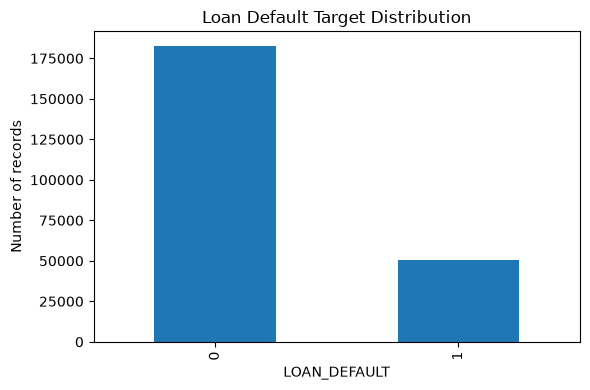

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
UNIQUEID,233154.0,NaN,NaN,NaN,535917.573376,68315.693711,417428.0,476786.25,535978.5,595039.75,671084.0
DISBURSED_AMOUNT,233154.0,NaN,NaN,NaN,54356.993528,12971.314171,13320.0,47145.0,53803.0,60413.0,990572.0
ASSET_COST,233154.0,NaN,NaN,NaN,75865.068144,18944.781289,37000.0,65717.0,70946.0,79201.75,1628992.0
LTV,233154.0,NaN,NaN,NaN,74.74653,11.456636,10.03,68.88,76.8,83.67,95.0
BRANCH_ID,233154.0,NaN,NaN,NaN,72.936094,69.834995,1.0,14.0,61.0,130.0,261.0
SUPPLIER_ID,233154.0,NaN,NaN,NaN,19638.635035,3491.949566,10524.0,16535.0,20333.0,23000.0,24803.0
MANUFACTURER_ID,233154.0,NaN,NaN,NaN,69.028054,22.141304,45.0,48.0,86.0,86.0,156.0
CURRENT_PINCODE_ID,233154.0,NaN,NaN,NaN,3396.880247,2238.147502,1.0,1511.0,2970.0,5677.0,7345.0
DATE_OF_BIRTH,233154,15433,01-01-1988,2173,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EMPLOYMENT_TYPE,225493,2,Self employed,127635,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# CELL 4 — Quick exploratory checks
print("Dataset shape:", df.shape)
print("Duplicate rows:", int(df.duplicated().sum()))
plt.figure(figsize=(6, 4))
df[TARGET_COLUMN].value_counts(dropna=False).sort_index().plot(kind="bar")
plt.title("Loan Default Target Distribution")
plt.xlabel(TARGET_COLUMN); plt.ylabel("Number of records")
plt.tight_layout(); plt.show()
display(df.describe(include="all").T.head(25))

In [6]:
# CELL 5 — Clean data, split, and create preprocessing pipeline
df_model = df.dropna(subset=[TARGET_COLUMN]).drop_duplicates().copy()
X = df_model.drop(columns=[TARGET_COLUMN]).copy()
y = df_model[TARGET_COLUMN].astype(str).copy()

# Drop known identifiers/high-cardinality ID-like fields from this dataset.
known_ids = {"UNIQUEID", "BRANCH_ID", "SUPPLIER_ID", "MANUFACTURER_ID", "CURRENT_PINCODE_ID", "STATE_ID", "EMPLOYEE_CODE_ID"}
id_columns = [c for c in X.columns if c.upper() in known_ids or c.lower().replace("_", "") in {"id", "uniqueid", "customerid", "loanid", "applicationid"}]
if id_columns:
    print("Dropping identifier columns:", id_columns)
    X = X.drop(columns=id_columns)

# Remove completely empty columns and text columns with too many unique values.
empty_columns = X.columns[X.isna().all()].tolist()
if empty_columns:
    print("Dropping completely empty columns:", empty_columns)
    X = X.drop(columns=empty_columns)
text_cols = X.select_dtypes(exclude=np.number).columns.tolist()
high_cardinality = [c for c in text_cols if X[c].nunique(dropna=True) > 100]
if high_cardinality:
    print("Dropping high-cardinality text/date columns to keep encoding manageable:", high_cardinality)
    X = X.drop(columns=high_cardinality)
if X.shape[1] == 0: raise ValueError("No feature columns remain after cleaning.")
if y.nunique() < 2: raise ValueError("Target has fewer than two classes.")
if int(y.value_counts().min()) < 2: raise ValueError("Each target class needs at least two rows for a stratified split.")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = [c for c in X_train.columns if c not in numeric_features]
numeric_preprocessor = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
# Dense one-hot output is needed by Gaussian Naive Bayes; high-cardinality text columns were removed above.
try:
    onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    onehot = OneHotEncoder(handle_unknown="ignore", sparse=False)
categorical_preprocessor = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", onehot)])
preprocessor = ColumnTransformer([("num", numeric_preprocessor, numeric_features), ("cat", categorical_preprocessor, categorical_features)])
print("Rows after cleaning:", len(df_model))
print("Train rows:", len(X_train), "| Test rows:", len(X_test))
print("Numeric features:", len(numeric_features), "| Categorical features:", len(categorical_features))
print("Target classes:", sorted(y.unique()))

Dropping identifier columns: ['UNIQUEID', 'BRANCH_ID', 'SUPPLIER_ID', 'MANUFACTURER_ID', 'CURRENT_PINCODE_ID', 'STATE_ID', 'EMPLOYEE_CODE_ID']
Dropping high-cardinality text/date columns to keep encoding manageable: ['DATE_OF_BIRTH', 'AVERAGE_ACCT_AGE', 'CREDIT_HISTORY_LENGTH']
Rows after cleaning: 233154
Train rows: 186523 | Test rows: 46631
Numeric features: 27 | Categorical features: 3
Target classes: ['0', '1']


In [15]:

# CELL 6 — Define the 10 required classification algorithms

RANDOM_STATE = 42

bagging_params = inspect.signature(BaggingClassifier).parameters

if "estimator" in bagging_params:
    bagging_model = BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
        n_estimators=10,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
else:
    bagging_model = BaggingClassifier(
        base_estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
        n_estimators=10,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

models = {
    "Logistic Regression (A)": LogisticRegression(
        max_iter=500,
        random_state=RANDOM_STATE
    ),
    "K-Nearest Neighbors (A)": KNeighborsClassifier(
        n_neighbors=5,
        n_jobs=-1
    ),
    "Gaussian Naive Bayes (A)": GaussianNB(),
    "Decision Tree (A)": DecisionTreeClassifier(
        random_state=RANDOM_STATE,
        max_depth=20
    ),
    "SVC - Linear SVM (A)": LinearSVC(
        random_state=RANDOM_STATE,
        max_iter=3000
    ),
    "Random Forest (B)": RandomForestClassifier(
        n_estimators=50,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        class_weight=None
    ),
    "AdaBoost (B)": AdaBoostClassifier(
        n_estimators=50,
        learning_rate=0.5,
        random_state=RANDOM_STATE
    ),
    "Gradient Boosting (B)": GradientBoostingClassifier(
        n_estimators=50,
        learning_rate=0.1,
        max_depth=2,
        random_state=RANDOM_STATE
    ),
    "Bagging (B)": bagging_model,
    "MLP Neural Network (B)": MLPClassifier(
        hidden_layer_sizes=(32,),
        activation="relu",
        max_iter=100,
        early_stopping=True,
        random_state=RANDOM_STATE
    )
}

print("Models defined:", len(models))
for name in models:
    print("-", name)


Models defined: 10
- Logistic Regression (A)
- K-Nearest Neighbors (A)
- Gaussian Naive Bayes (A)
- Decision Tree (A)
- SVC - Linear SVM (A)
- Random Forest (B)
- AdaBoost (B)
- Gradient Boosting (B)
- Bagging (B)
- MLP Neural Network (B)


In [17]:

# CELL 7 — Train and compare all 10 models (without clone)

results = []
fitted_models = {}
predictions = {}

def get_auc(pipe, X_eval, y_eval):
    try:
        model = pipe.named_steps["model"]

        if hasattr(pipe, "predict_proba"):
            scores = pipe.predict_proba(X_eval)
        elif hasattr(pipe, "decision_function"):
            scores = pipe.decision_function(X_eval)
        else:
            return np.nan

        if len(model.classes_) == 2:
            if np.ndim(scores) == 2:
                scores = scores[:, 1]

            return roc_auc_score(
                (np.asarray(y_eval) == model.classes_[1]).astype(int),
                scores
            )

        return roc_auc_score(
            y_eval, scores,
            multi_class="ovr",
            average="weighted",
            labels=model.classes_
        )
    except Exception as e:
        print("ROC-AUC unavailable:", repr(e))
        return np.nan


for name, estimator in models.items():
    print(f"\nTraining: {name}", flush=True)

    try:
        if name == "Random Forest (B)":
            estimator = RandomForestClassifier(
                n_estimators=50,
                random_state=42,
                n_jobs=-1,
                class_weight=None
            )

        X_fit, y_fit = X_train, y_train

        if name in {
            "K-Nearest Neighbors (A)",
            "SVC - Linear SVM (A)",
            "Random Forest (B)",
            "Gradient Boosting (B)",
            "Bagging (B)",
            "MLP Neural Network (B)"
        } and len(y_train) > 20000:
            X_fit, _, y_fit, _ = train_test_split(
                X_train, y_train,
                train_size=20000,
                random_state=42,
                stratify=y_train
            )

        # Create a fresh preprocessor and model pipeline
        from sklearn.base import clone as sklearn_clone
        fresh_preprocessor = sklearn_clone(preprocessor)

        pipe = Pipeline([
            ("preprocessor", fresh_preprocessor),
            ("model", estimator)
        ])

        try:
            pipe.fit(X_fit, y_fit)
        except Exception:
            import traceback
            print("FULL TRACEBACK:", name)
            traceback.print_exc()
            raise

        pred = pipe.predict(X_test)

        fitted_models[name] = pipe
        predictions[name] = pred

        results.append({
            "Model": name,
            "Accuracy": accuracy_score(y_test, pred),
            "Precision_weighted": precision_score(
                y_test, pred, average="weighted", zero_division=0
            ),
            "Recall_weighted": recall_score(
                y_test, pred, average="weighted", zero_division=0
            ),
            "F1_weighted": f1_score(
                y_test, pred, average="weighted", zero_division=0
            ),
            "ROC_AUC_OvR_or_binary": get_auc(pipe, X_test, y_test)
        })

        print("Completed:", name, flush=True)

    except Exception as e:
        print("MODEL FAILED:", name, "|", repr(e), flush=True)

        results.append({
            "Model": name,
            "Accuracy": np.nan,
            "Precision_weighted": np.nan,
            "Recall_weighted": np.nan,
            "F1_weighted": np.nan,
            "ROC_AUC_OvR_or_binary": np.nan
        })

classification_results = pd.DataFrame(results).sort_values(
    "F1_weighted", ascending=False, na_position="last"
).reset_index(drop=True)

display(classification_results.round(4))
print("\nSuccessfully trained:", len(fitted_models), "of", len(models))



Training: Logistic Regression (A)
Completed: Logistic Regression (A)

Training: K-Nearest Neighbors (A)
Completed: K-Nearest Neighbors (A)

Training: Gaussian Naive Bayes (A)
Completed: Gaussian Naive Bayes (A)

Training: Decision Tree (A)
Completed: Decision Tree (A)

Training: SVC - Linear SVM (A)
Completed: SVC - Linear SVM (A)

Training: Random Forest (B)
Completed: Random Forest (B)

Training: AdaBoost (B)
Completed: AdaBoost (B)

Training: Gradient Boosting (B)
Completed: Gradient Boosting (B)

Training: Bagging (B)
Completed: Bagging (B)

Training: MLP Neural Network (B)
Completed: MLP Neural Network (B)


,Model,Accuracy,Precision_weighted,Recall_weighted,F1_weighted,ROC_AUC_OvR_or_binary
0,K-Nearest Neighbors (A),0.7437,0.6784,0.7437,0.6998,0.5525
1,Decision Tree (A),0.7492,0.6762,0.7492,0.6985,0.5716
2,Random Forest (B),0.7731,0.6869,0.7731,0.6983,0.5800
3,Bagging (B),0.7625,0.6762,0.7625,0.6973,0.5521
4,Logistic Regression (A),0.7822,0.6881,0.7822,0.6888,0.6281
5,SVC - Linear SVM (A),0.7826,0.6942,0.7826,0.6884,0.6206
6,MLP Neural Network (B),0.7822,0.6711,0.7822,0.6880,0.5875
7,Gradient Boosting (B),0.7828,0.6750,0.7828,0.6877,0.6223
8,AdaBoost (B),0.7829,0.6130,0.7829,0.6876,0.6190
9,Gaussian Naive Bayes (A),0.4235,0.7031,0.4235,0.4493,0.5713



Successfully trained: 10 of 10



Logistic Regression (A)
              precision    recall  f1-score   support

           0       0.78      1.00      0.88     36509
           1       0.34      0.00      0.01     10122

    accuracy                           0.78     46631
   macro avg       0.56      0.50      0.44     46631
weighted avg       0.69      0.78      0.69     46631



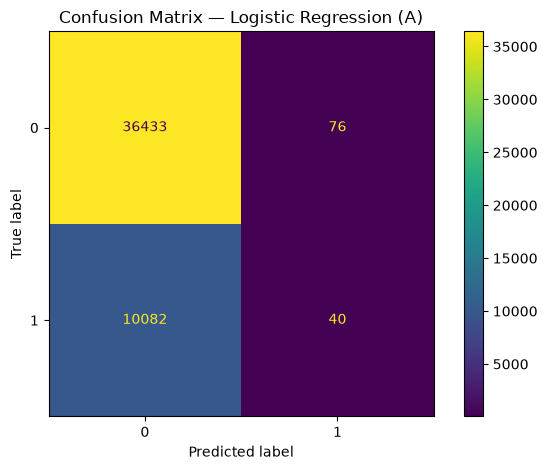


K-Nearest Neighbors (A)
              precision    recall  f1-score   support

           0       0.79      0.92      0.85     36509
           1       0.28      0.11      0.16     10122

    accuracy                           0.74     46631
   macro avg       0.53      0.52      0.51     46631
weighted avg       0.68      0.74      0.70     46631



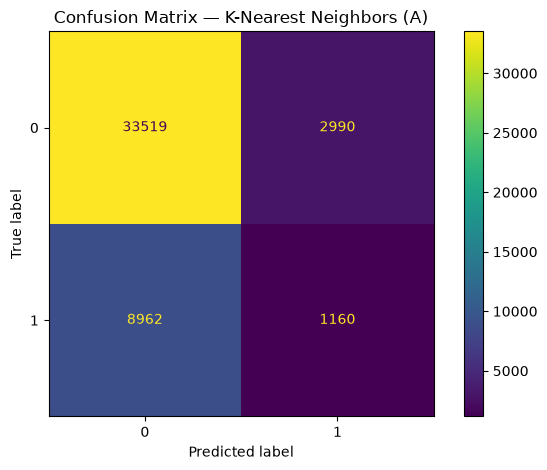


Gaussian Naive Bayes (A)
              precision    recall  f1-score   support

           0       0.83      0.33      0.47     36509
           1       0.24      0.76      0.36     10122

    accuracy                           0.42     46631
   macro avg       0.54      0.54      0.42     46631
weighted avg       0.70      0.42      0.45     46631



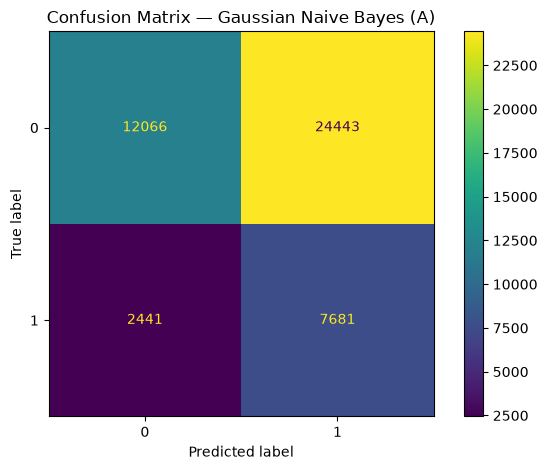


Decision Tree (A)
              precision    recall  f1-score   support

           0       0.79      0.93      0.85     36509
           1       0.27      0.09      0.14     10122

    accuracy                           0.75     46631
   macro avg       0.53      0.51      0.50     46631
weighted avg       0.68      0.75      0.70     46631



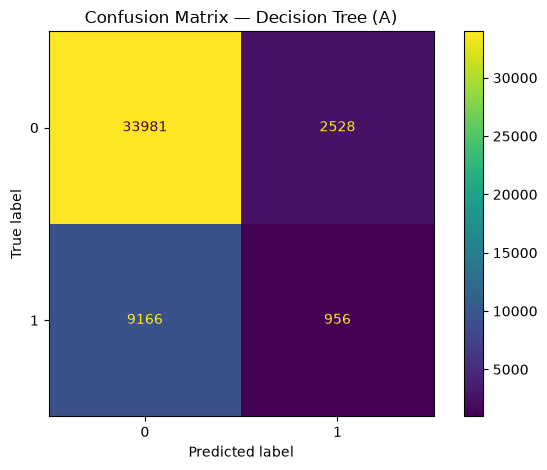


SVC - Linear SVM (A)
              precision    recall  f1-score   support

           0       0.78      1.00      0.88     36509
           1       0.37      0.00      0.00     10122

    accuracy                           0.78     46631
   macro avg       0.58      0.50      0.44     46631
weighted avg       0.69      0.78      0.69     46631



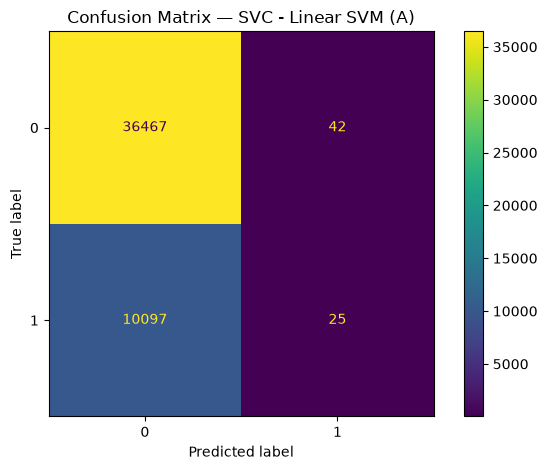


Random Forest (B)
              precision    recall  f1-score   support

           0       0.79      0.98      0.87     36509
           1       0.33      0.04      0.08     10122

    accuracy                           0.77     46631
   macro avg       0.56      0.51      0.47     46631
weighted avg       0.69      0.77      0.70     46631



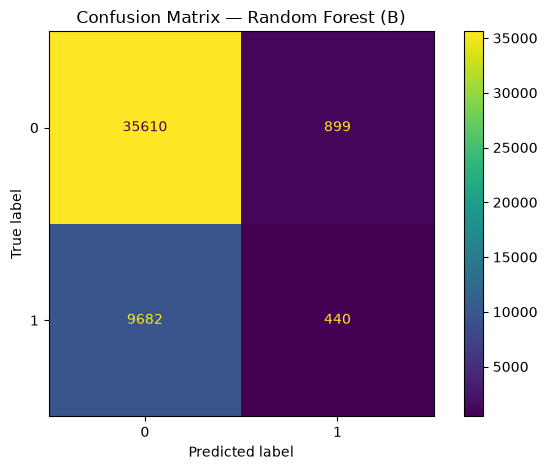


AdaBoost (B)
              precision    recall  f1-score   support

           0       0.78      1.00      0.88     36509
           1       0.00      0.00      0.00     10122

    accuracy                           0.78     46631
   macro avg       0.39      0.50      0.44     46631
weighted avg       0.61      0.78      0.69     46631



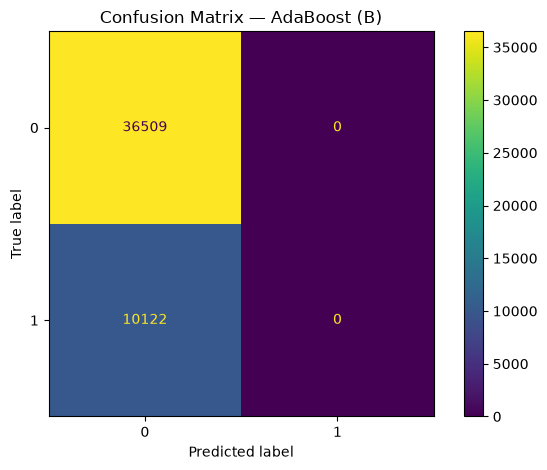


Gradient Boosting (B)
              precision    recall  f1-score   support

           0       0.78      1.00      0.88     36509
           1       0.29      0.00      0.00     10122

    accuracy                           0.78     46631
   macro avg       0.53      0.50      0.44     46631
weighted avg       0.68      0.78      0.69     46631



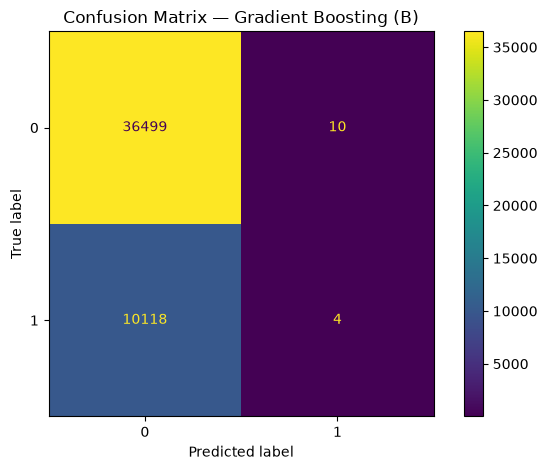


Bagging (B)
              precision    recall  f1-score   support

           0       0.79      0.96      0.86     36509
           1       0.28      0.06      0.10     10122

    accuracy                           0.76     46631
   macro avg       0.53      0.51      0.48     46631
weighted avg       0.68      0.76      0.70     46631



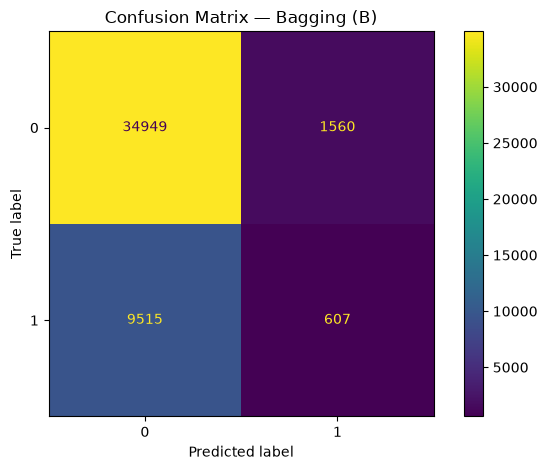


MLP Neural Network (B)
              precision    recall  f1-score   support

           0       0.78      1.00      0.88     36509
           1       0.27      0.00      0.00     10122

    accuracy                           0.78     46631
   macro avg       0.53      0.50      0.44     46631
weighted avg       0.67      0.78      0.69     46631



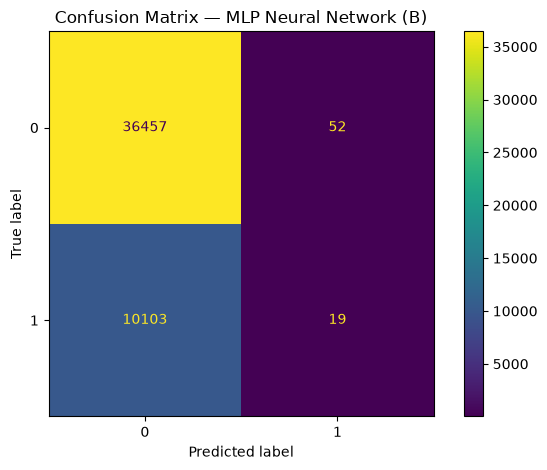

In [18]:
# CELL 8 — Confusion matrices and classification reports
for name, y_pred in predictions.items():
    print("\n" + "=" * 70 + "\n" + name)
    print(classification_report(y_test, y_pred, zero_division=0))
    labels = sorted(pd.Series(y_train).unique())
    cm = confusion_matrix(y_test, y_pred, labels=labels)
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels).plot(values_format="d")
    plt.title("Confusion Matrix — " + name)
    plt.tight_layout(); plt.show()

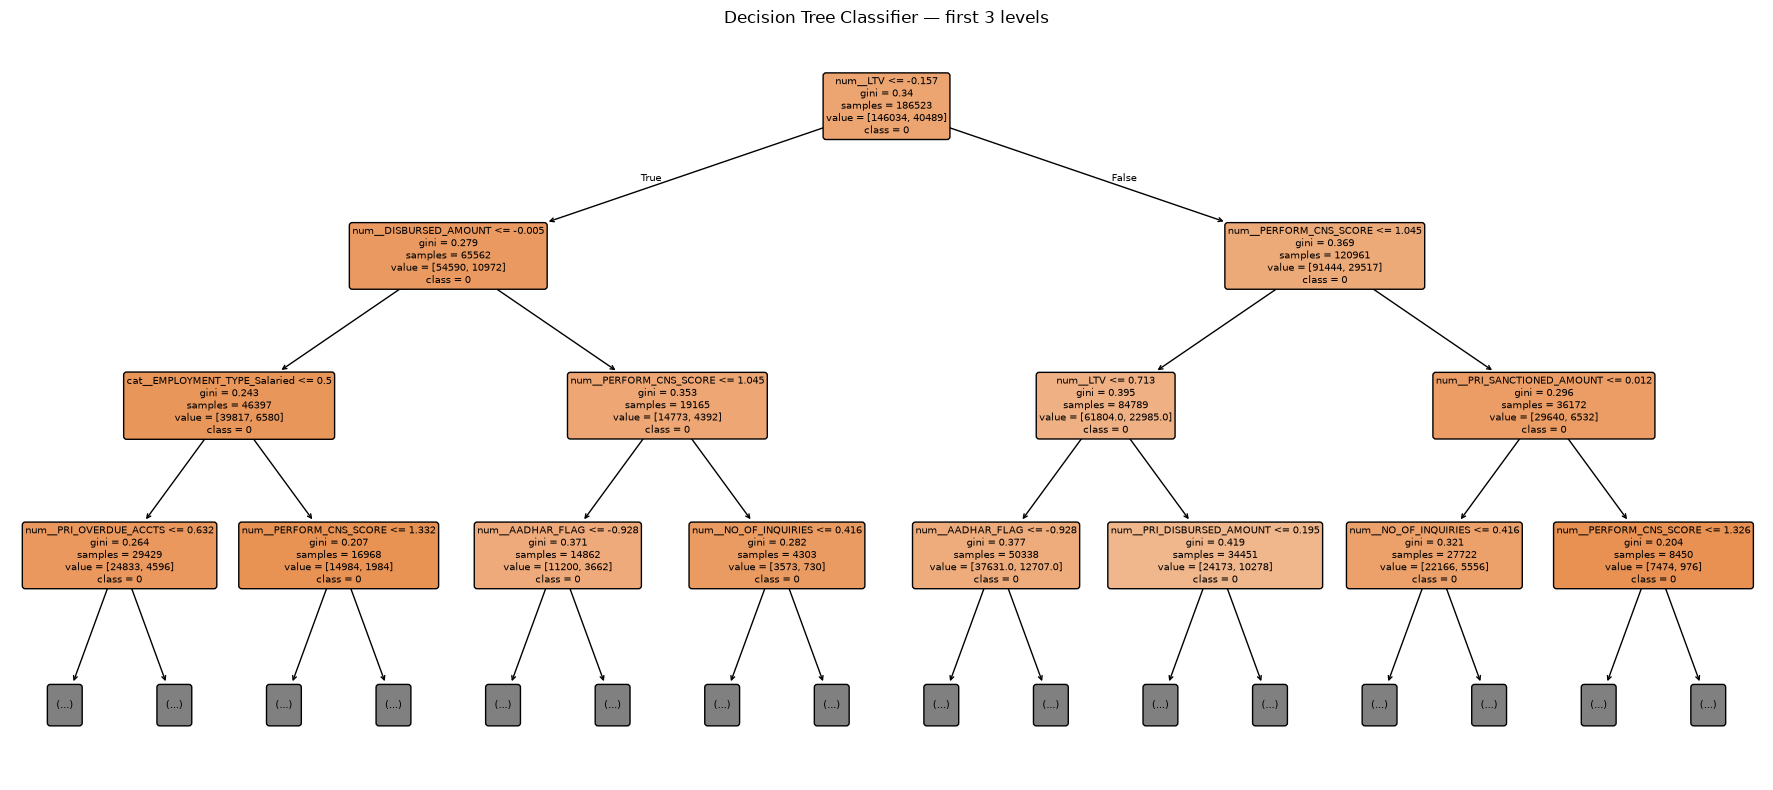

In [19]:
# CELL 9 — Visualise the Decision Tree, if it trained successfully
if "Decision Tree (A)" in fitted_models:
    tree_pipe = fitted_models["Decision Tree (A)"]
    tree_model = tree_pipe.named_steps["model"]
    try:
        feature_names = tree_pipe.named_steps["preprocessor"].get_feature_names_out()
        plt.figure(figsize=(18, 8))
        plot_tree(tree_model, feature_names=feature_names, class_names=[str(c) for c in tree_model.classes_], filled=True, rounded=True, max_depth=3, fontsize=7)
        plt.title("Decision Tree Classifier — first 3 levels")
        plt.tight_layout(); plt.show()
    except Exception as e:
        print("Tree plot could not be generated:", repr(e))
else:
    print("Decision Tree model was not fitted; skipping plot.")

In [22]:
# CELL 10 — Random Forest Hyperparameter Tuning

from sklearn.model_selection import GridSearchCV

# Reuse the already-trained Random Forest pipeline
rf_pipeline = fitted_models["Random Forest (B)"]

# Explicitly remove the invalid class-weight setting
rf_pipeline.set_params(model__class_weight=None)

# Test 3 configurations, with 3-fold cross-validation
rf_param_grid = [
    {
        "model__n_estimators": [50],
        "model__max_depth": [10],
        "model__class_weight": [None]
    },
    {
        "model__n_estimators": [100],
        "model__max_depth": [20],
        "model__class_weight": [None]
    },
    {
        "model__n_estimators": [100],
        "model__max_depth": [None],
        "model__class_weight": [None]
    }
]

rf_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    cv=3,
    scoring="f1_weighted",
    n_jobs=-1,
    error_score="raise",
    verbose=1
)

rf_search.fit(X_train, y_train)

best_rf = rf_search.best_estimator_
rf_predictions = best_rf.predict(X_test)

print("Random Forest tuning completed.")
print("Best parameters:", rf_search.best_params_)
print("Best cross-validation F1:", round(rf_search.best_score_, 4))

# Save the tuned model and predictions
fitted_models["Random Forest (B) - Tuned"] = best_rf
predictions["Random Forest (B) - Tuned"] = rf_predictions

Fitting 3 folds for each of 3 candidates, totalling 9 fits
Random Forest tuning completed.
Best parameters: {'model__class_weight': None, 'model__max_depth': None, 'model__n_estimators': 100}
Best cross-validation F1: 0.6996


In [23]:
top_two_names = classification_results["Model"].head(2).tolist()
print("Top two models selected from test comparison:", top_two_names)
print("Note: for a strict model-selection workflow, choose models using validation/CV data rather than the test set.")

cv_rows = []
for name in top_two_names:
    estimator = models[name]
    pipe = Pipeline(steps=[("preprocessor", preprocessor), ("model", estimator)])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1_weighted", n_jobs=-1)
    cv_rows.append({
        "Model": name,
        "CV weighted F1 mean": scores.mean(),
        "CV weighted F1 std": scores.std(),
        "CV folds": len(scores)
    })
cv_results = pd.DataFrame(cv_rows).sort_values("CV weighted F1 mean", ascending=False)
display(cv_results.round(4))

Top two models selected from test comparison: ['K-Nearest Neighbors (A)', 'Decision Tree (A)']
Note: for a strict model-selection workflow, choose models using validation/CV data rather than the test set.


,Model,CV weighted F1 mean,CV weighted F1 std,CV folds
0,K-Nearest Neighbors (A),0.7022,0.0012,3
1,Decision Tree (A),0.6986,0.0013,3


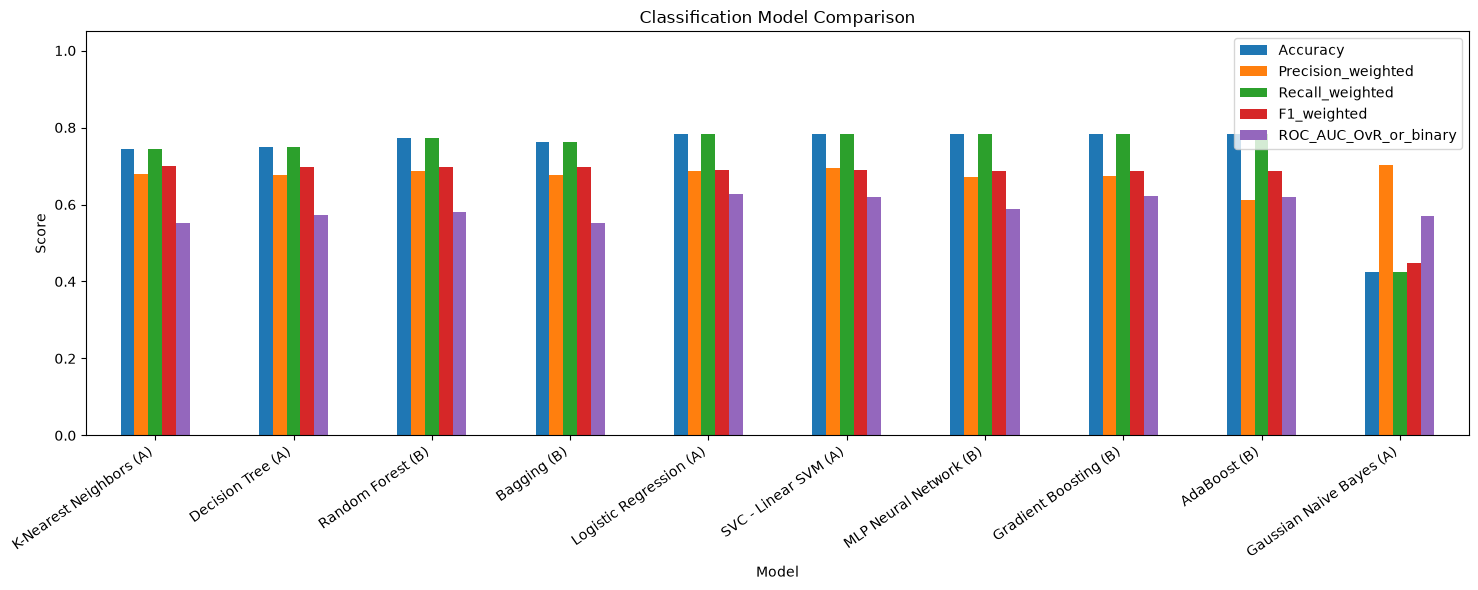

In [24]:
plot_df = classification_results.set_index("Model")[[
    "Accuracy", "Precision_weighted", "Recall_weighted", "F1_weighted", "ROC_AUC_OvR_or_binary"
]]
plot_df.plot(kind="bar", figsize=(15, 6))
plt.title("Classification Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

In [25]:
classification_results.to_csv("classification_all_10_models.csv", index=False)
cv_results.to_csv("classification_top_models_cross_validation.csv", index=False)
print("Saved:")
print("- classification_all_10_models.csv")
print("- classification_top_models_cross_validation.csv")

Saved:
- classification_all_10_models.csv
- classification_top_models_cross_validation.csv
